In [68]:
# Walk up to repo root (identified by README.md)
.root <- getwd()
while (!file.exists(file.path(.root, 'README.md')) && dirname(.root) != .root)
  .root <- dirname(.root)
setwd(.root)
rm(.root)

suppressPackageStartupMessages({
  library(tidyverse)
  library(data.table)
  library(arrow)
  library(ggthemes)
  library(scales)
  library(patchwork)
})

options(repr.plot.width = 14, repr.plot.height = 8)

BASE_THEME <- theme_fivethirtyeight() +
  theme(
    axis.title        = element_text(size = 14),
    axis.text         = element_text(size = 13),
    panel.background  = element_rect(fill = "white", color = NA),
    plot.background   = element_rect(fill = "white", color = NA),
    legend.background = element_rect(fill = "white", color = NA),
    legend.text       = element_text(size = 12),
    legend.title      = element_text(size = 13),
    strip.text        = element_text(size = 14, face = "bold"),
    plot.title        = element_text(size = 20, face = "bold"),
    plot.subtitle     = element_text(size = 13)
  )
theme_set(BASE_THEME)

COMMIT_MS  <- 150

PITCH_NAMES <- c(
  FF = "4-Seam",    SI = "Sinker",    FC = "Cutter",
  CH = "Changeup",  FS = "Splitter",
  SL = "Slider",    CU = "Curveball", ST = "Sweeper",   KC = "Knuckle-curve"
)

PITCH_COLORS <- c(
  FF = "#d62728", SI = "#ff7f0e", FC = "#e377c2",
  CH = "#2ca02c", FS = "#17becf",
  SL = "#bcbd22", CU = "#1f77b4", ST = "#9467bd", KC = "#8c564b"
)

In [69]:
pc_sample        <- read_csv("data/viz_cache/pc_sample.csv",          show_col_types = FALSE) |>
  mutate(pitch_name = factor(PITCH_NAMES[pitch_type], levels = unname(PITCH_NAMES)))
pc_deception     <- read_csv("data/viz_cache/pc_deception.csv",        show_col_types = FALSE) |>
  mutate(pitch_name = factor(pitch_name, levels = unname(PITCH_NAMES)))
pc_sens          <- read_csv("data/viz_cache/pc_sensitivity.csv",       show_col_types = FALSE) |>
  mutate(pitch_name = factor(pitch_name, levels = unname(PITCH_NAMES)))
pc_count_dev     <- read_csv("data/viz_cache/pc_count_dev.csv",         show_col_types = FALSE)
pc_baseline_cmp  <- read_csv("data/viz_cache/pc_baseline_compare.csv",  show_col_types = FALSE) |>
  mutate(
    baseline        = factor(baseline, levels = c("Empirical (KNN)", "Linear (trajectory)")),
    quartile_label  = factor(quartile, labels = c("Q1\n(least)", "Q2", "Q3", "Q4\n(most)"))
  )

cat(sprintf(
  "Cache loaded | pc_sample: %s rows | pitch types: %s\n",
  formatC(nrow(pc_sample), format = "d", big.mark = ","),
  paste(sort(unique(pc_sample$pitch_type)), collapse = ", ")
))

Cache loaded | pc_sample: 30,000 rows | pitch types: CH, CU, FC, FF, FS, KC, SI, SL, ST


## Post-Commit Deviation Distributions

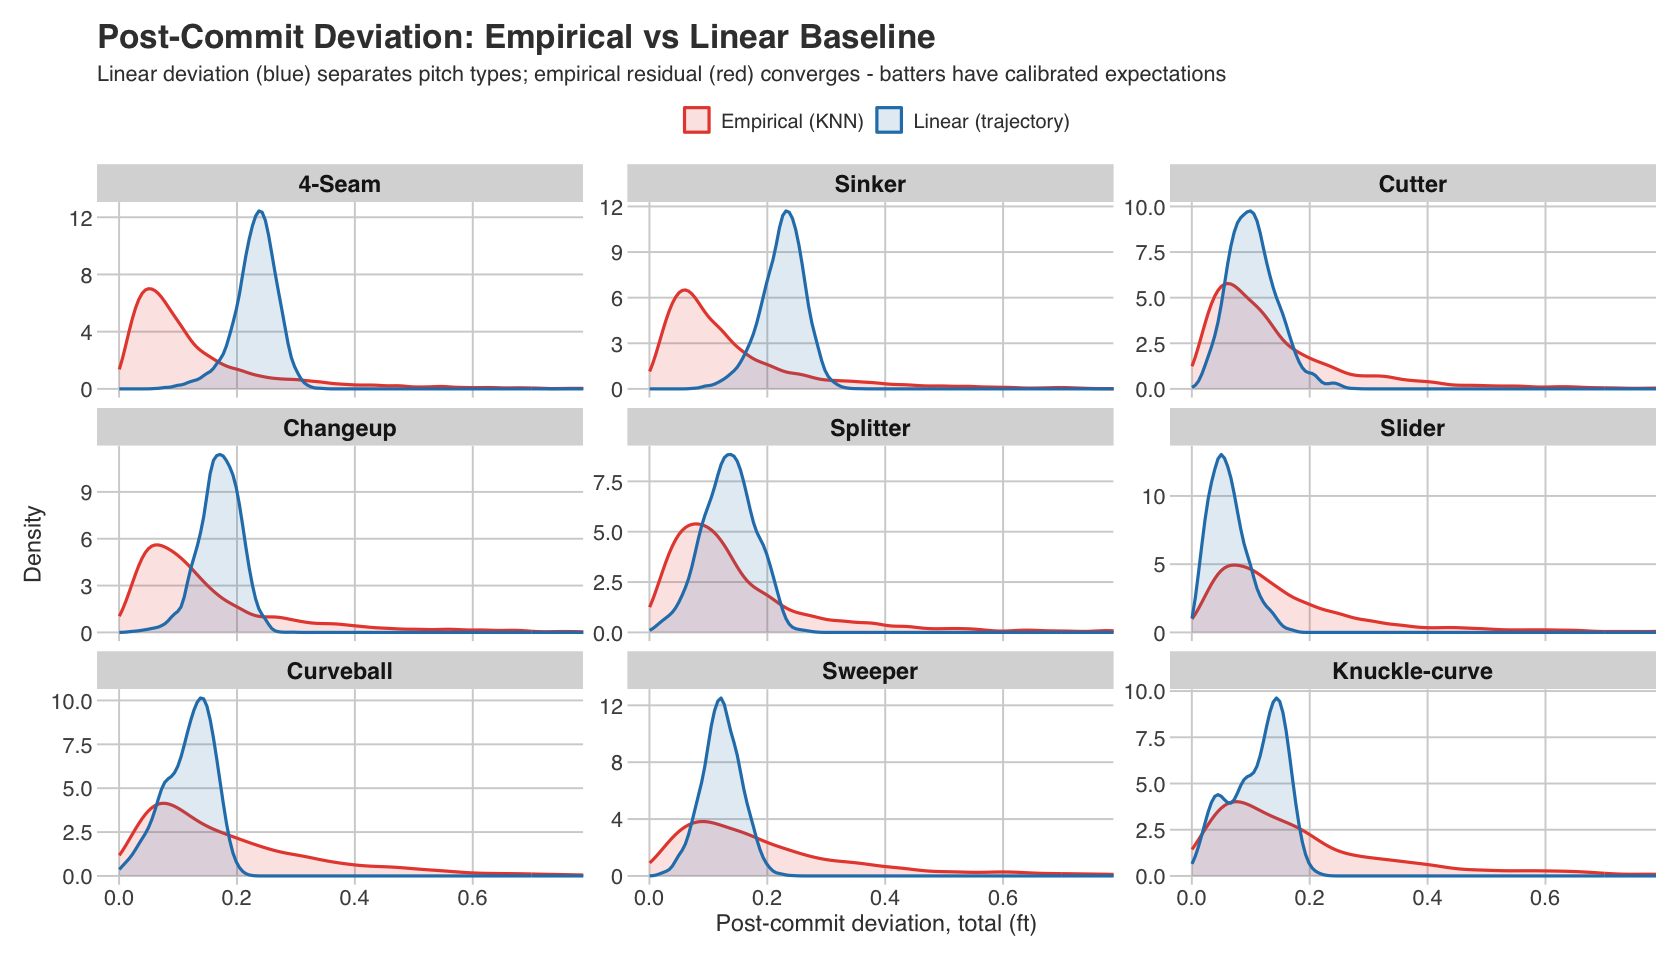

In [70]:
pc_sample |>
  pivot_longer(
    cols      = c(emp_dev_total, lin_dev_total),
    names_to  = "baseline",
    values_to = "dev_total"
  ) |>
  mutate(baseline = recode(baseline,
    emp_dev_total = "Empirical (KNN)",
    lin_dev_total = "Linear (trajectory)"
  )) |>
  ggplot(aes(x = dev_total, color = baseline, fill = baseline)) +
  geom_density(alpha = 0.15, linewidth = 0.9) +
  facet_wrap(~ pitch_name, nrow = 3, scales = "free_y") +
  coord_cartesian(xlim = c(0, 0.75)) +
  scale_color_manual(values = c("Empirical (KNN)" = "#e74c3c", "Linear (trajectory)" = "#2980b9"),
                     name = NULL) +
  scale_fill_manual(values  = c("Empirical (KNN)" = "#e74c3c", "Linear (trajectory)" = "#2980b9"),
                    name = NULL) +
  labs(
    title    = "Post-Commit Deviation: Empirical vs Linear Baseline",
    subtitle = "Linear deviation (blue) separates pitch types; empirical residual (red) converges - batters have calibrated expectations",
    x        = "Post-commit deviation, total (ft)",
    y        = "Density"
  ) +
  theme(legend.position = "top")

## Empirical vs. Linear Baseline

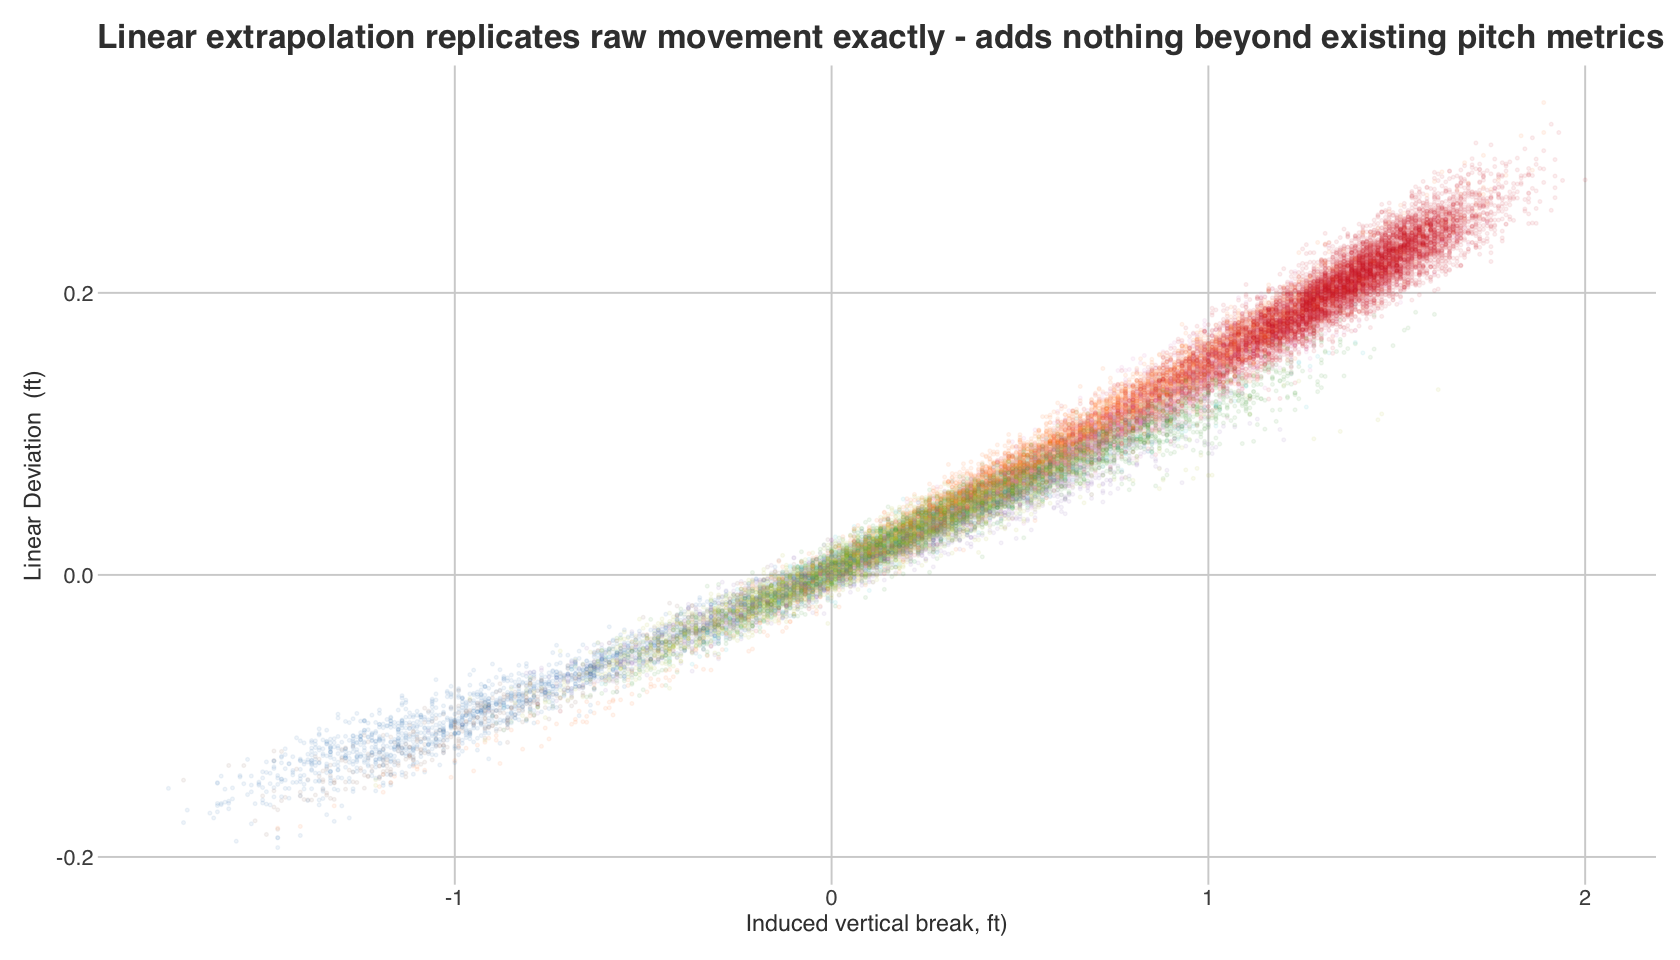

In [71]:
r_lin <- cor(pc_sample$pfx_z, pc_sample$pc150_dev_z, use = "complete.obs")

ggplot(pc_sample, aes(x = pfx_z, y = pc150_dev_z, color = pitch_type)) +
  geom_point(alpha = 0.07, size = 0.7, show.legend = FALSE) +
  scale_color_manual(values = PITCH_COLORS) +
  labs(
    title = "Linear extrapolation replicates raw movement exactly - adds nothing beyond existing pitch metrics",
    x        = "Induced vertical break, ft)",
    y        = "Linear Deviation  (ft)"
  )

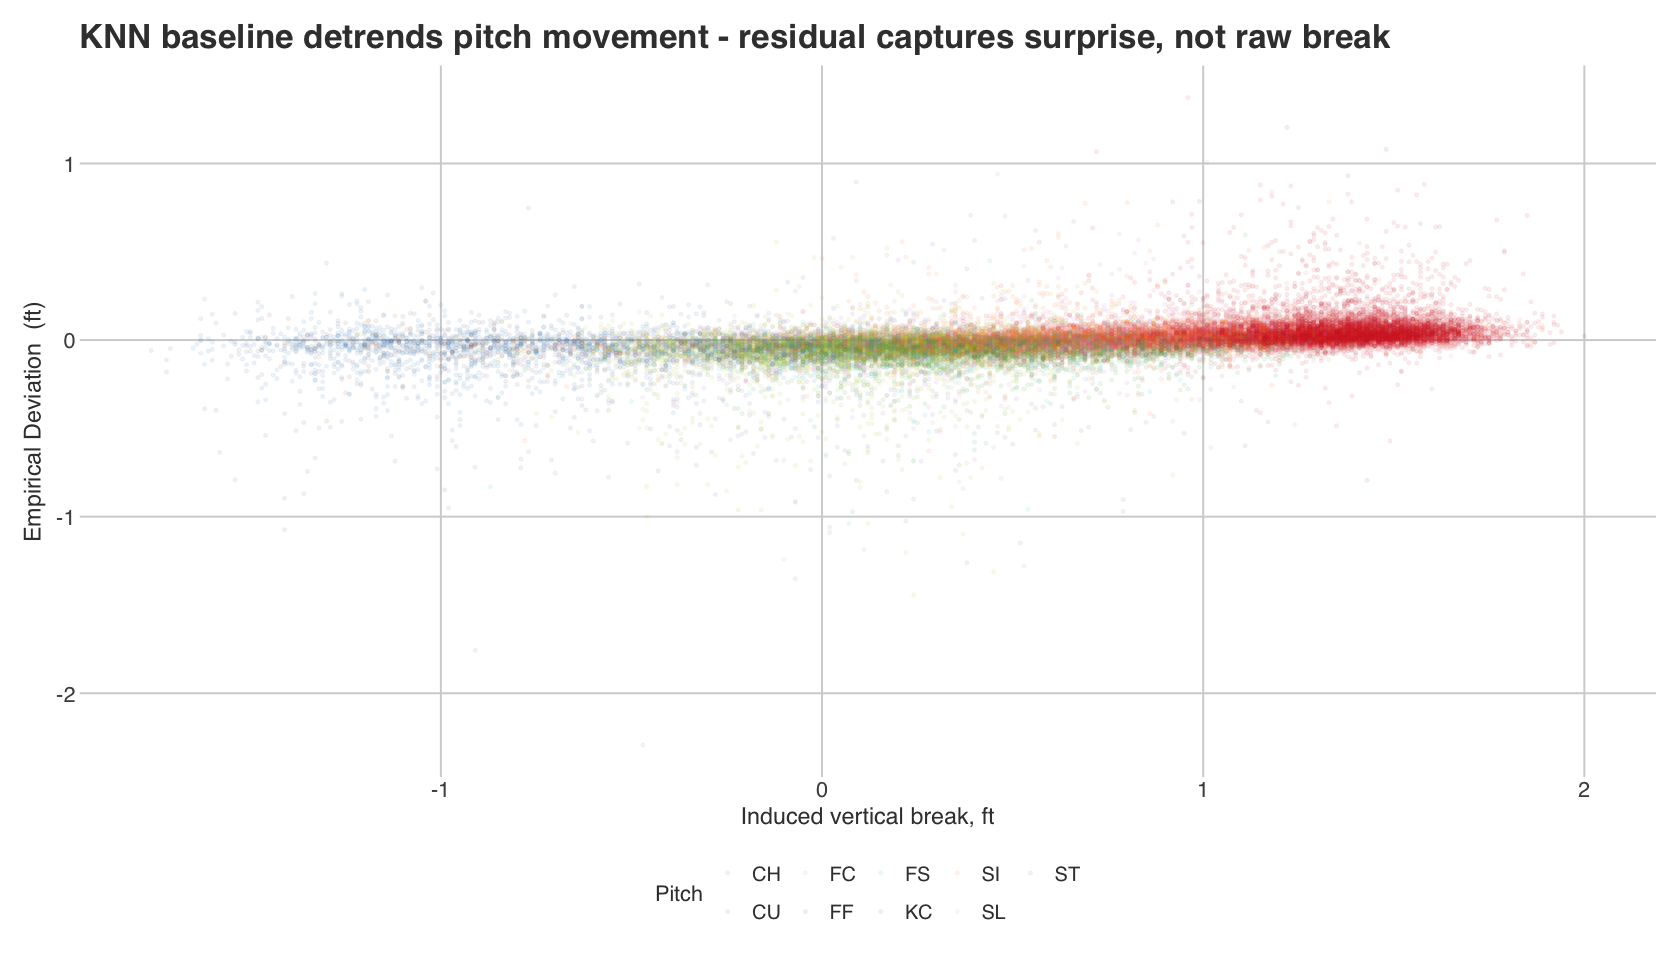

In [72]:
r_emp <- cor(pc_sample$pfx_z, pc_sample$pc150_emp_dev_z, use = "complete.obs")

ggplot(pc_sample, aes(x = pfx_z, y = pc150_emp_dev_z, color = pitch_type)) +
  geom_point(alpha = 0.07, size = 0.7) +
  scale_color_manual(values = PITCH_COLORS, name = "Pitch") +
  labs(
    title = "KNN baseline detrends pitch movement - residual captures surprise, not raw break",
    x        = "Induced vertical break, ft",
    y        = "Empirical Deviation  (ft)"
  )

## Why KNN Over Linear Trajectory?

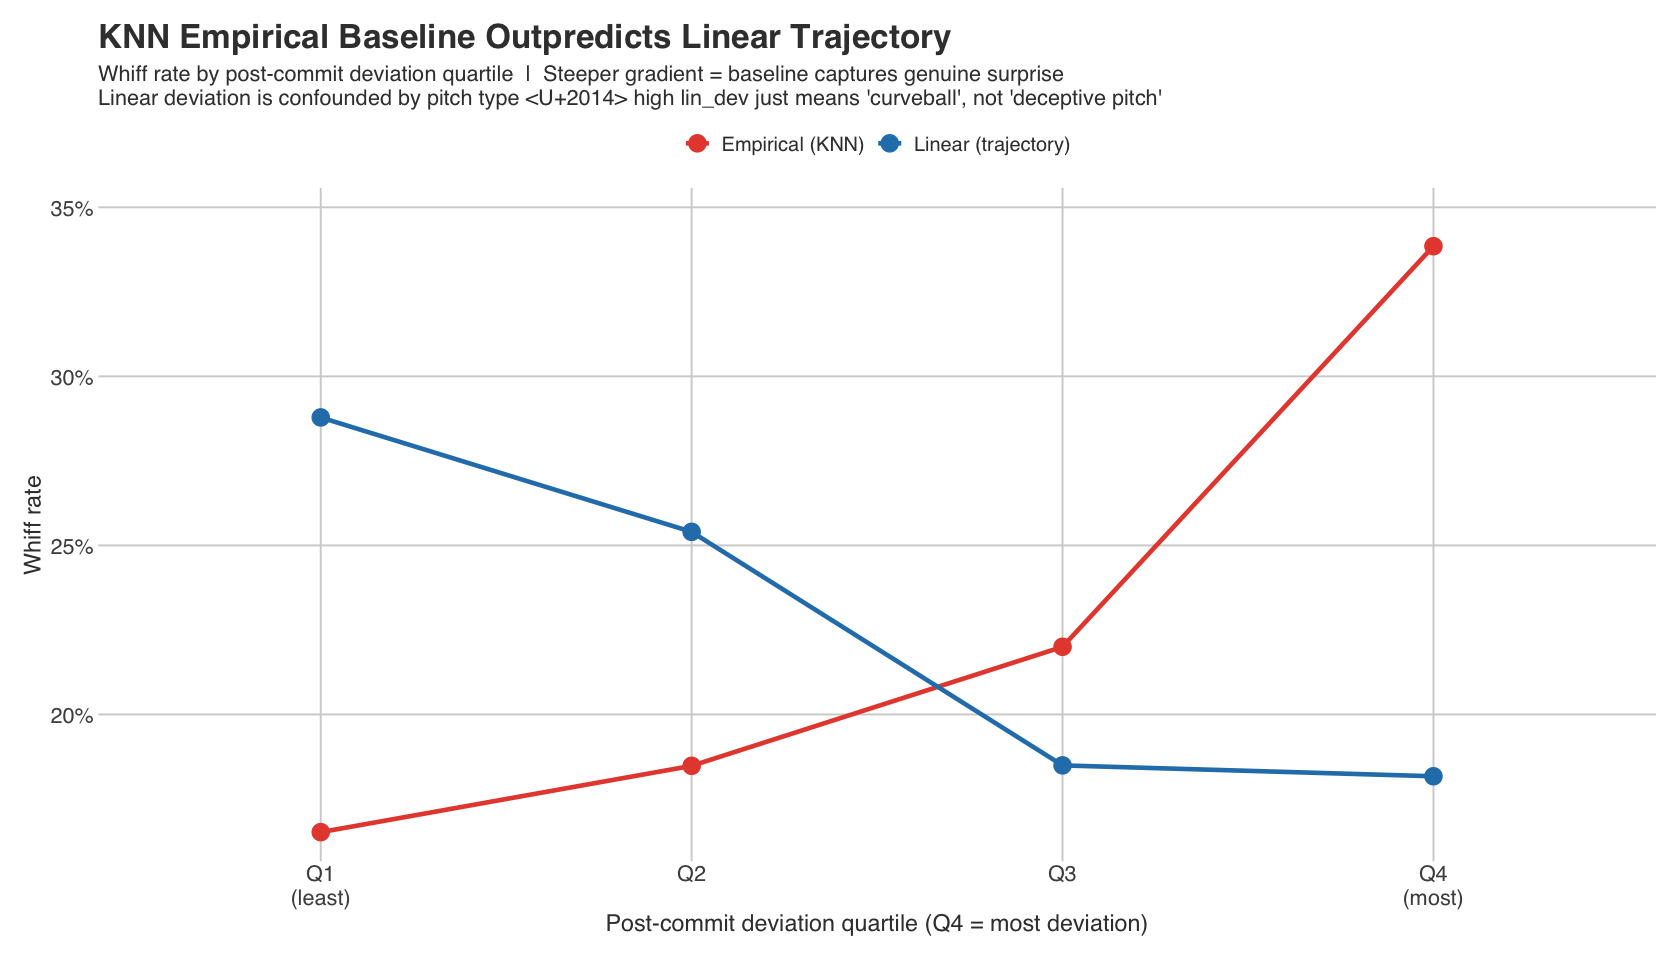

In [73]:
ggplot(pc_baseline_cmp,
       aes(x = quartile_label, y = whiff_rate,
           color = baseline, group = baseline)) +
  geom_line(linewidth = 1.3) +
  geom_point(size = 4.5) +
  scale_color_manual(
    values = c("Empirical (KNN)" = "#e74c3c", "Linear (trajectory)" = "#2980b9"),
    name   = NULL
  ) +
  scale_y_continuous(labels = percent_format(accuracy = 1),
                     expand = expansion(mult = c(0.05, 0.1))) +
  labs(
    title    = "KNN Empirical Baseline Outpredicts Linear Trajectory",
    subtitle = "Whiff rate by post-commit deviation quartile  |  Steeper gradient = baseline captures genuine surprise\nLinear deviation is confounded by pitch type — high lin_dev just means 'curveball', not 'deceptive pitch'",
    x        = "Post-commit deviation quartile (Q4 = most deviation)",
    y        = "Whiff rate"
  ) +
  theme(legend.position = "top")

## Deception Ratio by Pitch Type

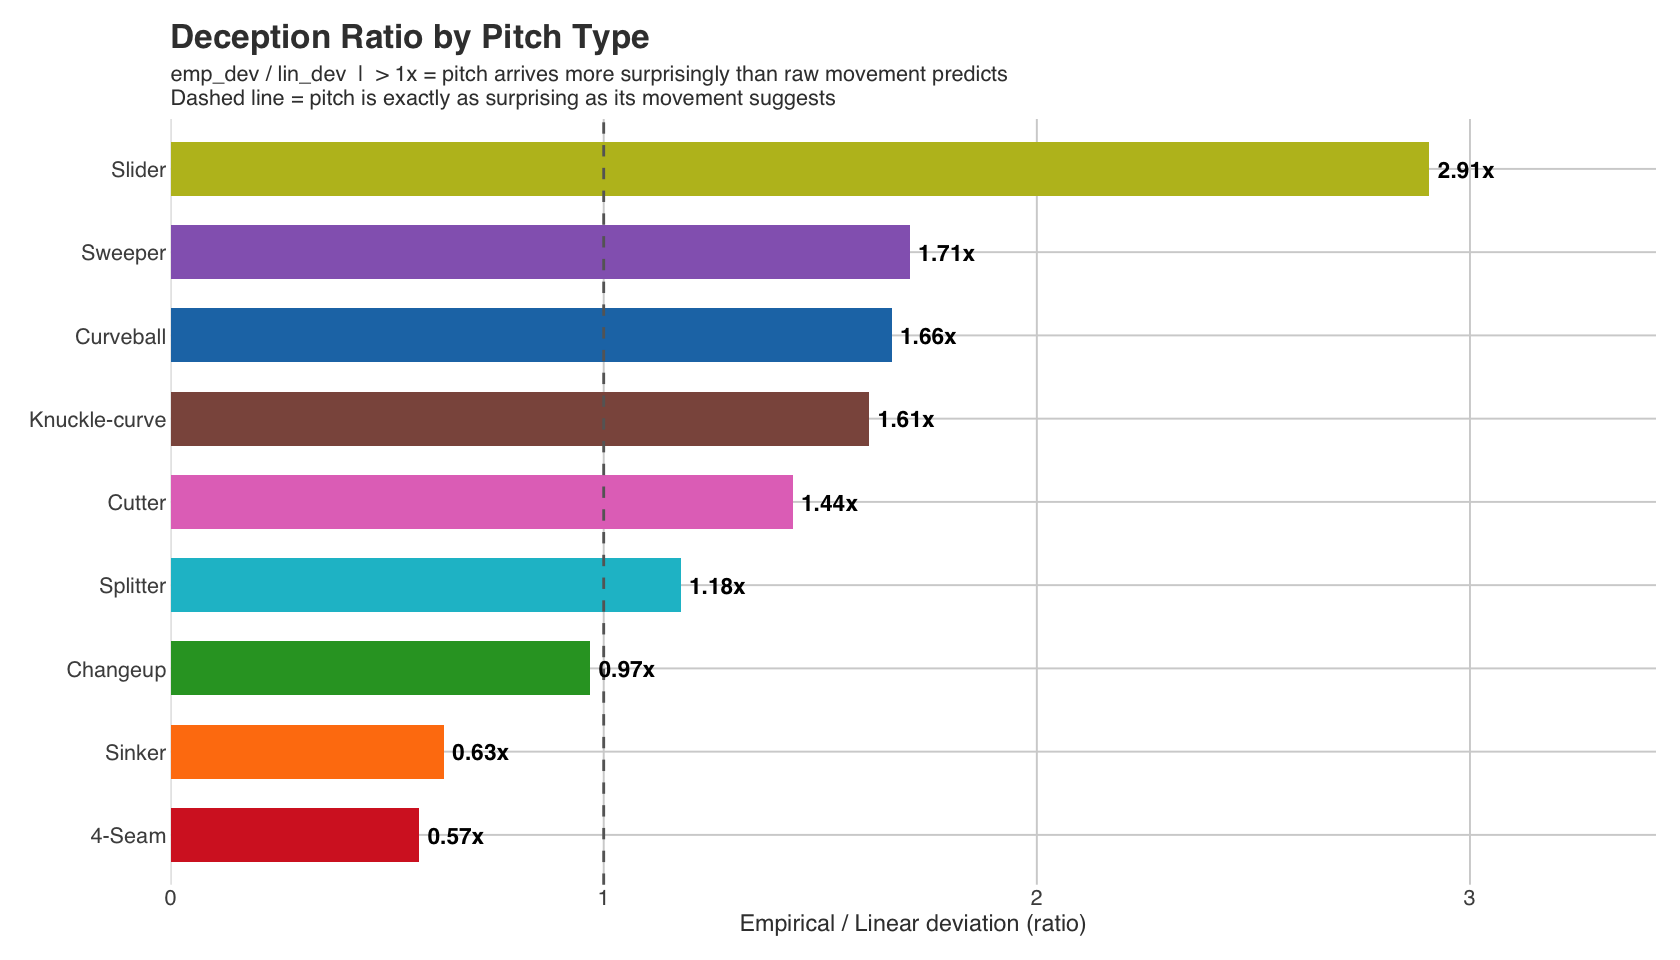

In [74]:
ggplot(pc_deception,
       aes(x = reorder(pitch_name, emp_lin_ratio),
           y = emp_lin_ratio, fill = pitch_type)) +
  geom_col(width = 0.65) +
  geom_hline(yintercept = 1, linetype = "dashed", color = "grey40", linewidth = 0.8) +
  geom_text(aes(label = sprintf("%.2fx", emp_lin_ratio)),
            hjust = -0.15, size = 4.8, fontface = "bold") +
  scale_fill_manual(values = PITCH_COLORS, guide = "none") +
  scale_y_continuous(expand = expansion(mult = c(0, 0.18))) +
  coord_flip() +
  labs(
    title    = "Deception Ratio by Pitch Type",
    subtitle = "emp_dev / lin_dev  |  > 1x = pitch arrives more surprisingly than raw movement predicts\nDashed line = pitch is exactly as surprising as its movement suggests",
    x        = NULL,
    y        = "Empirical / Linear deviation (ratio)"
  )